---

# Food System Resilience Prediction - DSC RASIO 10.0

*A non-pretrained CatBoost incumbent and a forward-fitted post-harvest proxy for 2026 forecasting.*

---

## RASIO-UNPAD

- Model: CatBoost trained from scratch on official data
- Technique: Causal target and spatial history with an out-of-fold post-harvest proxy
- Version: v26
- Status: final submission notebook; model selected by historical validation, not Public score

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Dataset Assembly**](#3)
4. [**Exploratory Data Analysis**](#4)
5. [**Preprocessing**](#5)
6. [**Temporal Target Feature Engineering**](#6)
7. [**Spatial Neighbor Feature Engineering**](#7)
8. [**Feature Audit**](#8)
9. [**Post-Harvest Proxy Engineering**](#9)
10. [**Walk-Forward Validation Design**](#10)
11. [**Temporal Baseline Diagnostics**](#11)
12. [**Modeling**](#12)
13. [**Evaluation**](#13)
14. [**Explainability**](#14)
15. [**Final Training and 2026 Inference**](#15)
16. [**Submission**](#16)
17. [**Post-Analysis**](#17)
18. [**Conclusion**](#18)

---

# Introduction <a name="1"></a>

---

The notebook tests whether a legal proxy for unavailable 2026 post-harvest assessments improves the frozen V25 CatBoost incumbent. The incumbent remains the default until paired historical validation supports a replacement.

## Overview

*The task predicts `food_system_resilience_index` for 358 regions in 2026. The true same-year post-harvest assessment is absent at inference, so it is never used directly as a resilience-model feature.*

## Aim

*The experiment compares the exact V25/V22 non-pretrained model with the same CatBoost learner plus a forward-trained post-harvest proxy. Both use identical rolling years and seed sets.*

## Metric

***Root Mean Squared Error (RMSE)** is the competition metric; lower is better. Validation scores are computed from held-out historical outcomes, never from 2026 labels.*

$$\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}$$

## Dataset

*Only the active official competition files are accepted. Labels end in 2025, predictors extend through 2026, and the official neighbor graph supplies causal spatial context.*

**Attributes**

1. `region_id`, `year`, and current official predictors
2. Own and neighbor target histories through the previous year
3. Forward-predicted `post_harvest_proxy`

**Target**

`food_system_resilience_index`: 2026 regional resilience score.

## Approach: CatBoost and a Forward Post-Harvest Proxy

*The reference is V25 CatBoost on the frozen 61-feature F_N contract. A second, scratch-trained CatBoost predicts post-harvest only from deployable inputs. Its historical predictions are strictly forward in time and are added as one extra feature for a challenger CatBoost.*

```text
Official data -> causal history and graph -> incumbent CatBoost
                                 -> forward post-harvest proxy -> challenger CatBoost
Same nested rolling folds -> deployment-year and seed checks -> selected 2026 prediction
```

---

# Initialization <a name="2"></a>

---

The environment, seed, official input path, and fixed model contract are set before data processing. The final notebook runs standalone on Kaggle.

## Environment Setup

CatBoost uses the CPU Ordered configuration to reproduce the V25/V22 incumbent. A GPU is optional for viewing the environment, not required for fitting.

In [1]:
!nvidia-smi || true

Sun Sep 27 14:58:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs all libraries used in this notebook.

In [2]:
%pip install -q catboost==1.2.10 numpy==2.0.2 pandas==2.3.3 matplotlib==3.10.0 scipy==1.16.3 scikit-learn==1.6.1

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Every import is centralized here; no pretrained model or checkpoint is loaded.

In [3]:
from pathlib import Path
from importlib.metadata import version
from catboost import CatBoostRegressor, Pool
import gc, hashlib, json, os, platform, random, sys, time, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import optimize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

VERSION = 'v26'
TARGET = 'food_system_resilience_index'
TARGET_YEAR = 2026
HISTORY_START = 2013
OUTER_YEARS = list(range(2018, 2026))
RECENT_YEARS = [2023, 2024, 2025]
DEPLOY_YEARS = [2024, 2025]                     # V25 gate A: covariate-closest folds to 2026 (AUC 0.55 / 0.50)
EXPECTED_REGIONS = 358
EXPECTED_PANEL_ROWS = 358 * 17
PH_COL = 'post_harvest_assessment.post_harvest_assessment_score'
RAW_TARGET = '_official_target_history_raw'
CAT_COLS = ['region_id', 'country', 'climate_zone']
ANNUAL = ['climate', 'agriculture', 'economy', 'logistics', 'social_nutrition',
          'shock_history', 'auxiliary_indicators', 'post_harvest_assessment']
BLOCKS = [b for b in ANNUAL if b != 'post_harvest_assessment']
GLOBAL_FLAGS = {f'climate.{x}' for x in ['elnino_year', 'lanina_year', 'pandemic_period',
                                        'fuel_shock_year', 'rice_price_shock_year']}

# Seed policy (V25 final report): the current best reproducible system is V22 CatBoost F_N with 5 seeds, kept unchanged.
# The exact V22 seed set is retained. More seeds were not adopted: Probe 06 showed Public seed luck is not evidence.
SEEDS = [2026, 2027, 2028, 2029, 2030]
XAI_SEED = 2026
CB_CFG = dict(depth=6, learning_rate=0.03, l2_leaf_reg=5.0, max_iterations=2000, early_stopping_rounds=100)
# Device: the V22 anchor is CPU Ordered boosting, and only the CPU path reproduces the V22 vector exactly.
# GPU CatBoost changes split scoring, so it is opt-in (RASIO_CB_DEVICE=GPU) with automatic CPU fallback.
CB_DEVICE = os.environ.get('RASIO_CB_DEVICE', 'CPU').upper()
THREADS = max(1, os.cpu_count() or 1)
# V25 gate constants (V25_VALIDATION_SPEC.md)
FLOOR_HEADROOM = 0.03          # gate C: legal headroom over V22 under the diagnosed process (achievable floor ~9.32 vs 9.349)
TAIL_MAX_SHARE = 0.5           # gate D: max share of OOF gain from the top-5% changed rows
NEFF_MIN = 80                  # gate D: effective rows carrying the 2026 change
MIN_SEED_PASS = 4              # gate A for stochastic challengers: >= 4/5 paired seeds must pass the 2024-25 veto
N_BOOT = 1000

WORK = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
RESULTS_DIR = WORK / 'results' / VERSION
SUB_DIR = WORK / 'submissions' / VERSION
for d in (RESULTS_DIR, SUB_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(2026)
np.random.seed(2026)
RUNTIME = {}
T_START = time.time()
print('RASIO V26 | Python', sys.version.split()[0], '|', platform.platform())
print('CPU threads:', THREADS, '| CatBoost device:', CB_DEVICE, '| seeds:', SEEDS)
print('results ->', RESULTS_DIR, '| submissions ->', SUB_DIR)

RASIO V26 | Python 3.12.13 | Linux-6.12.90+-x86_64-with-glibc2.35
CPU threads: 4 | CatBoost device: CPU | seeds: [2026, 2027, 2028, 2029, 2030]
results -> /kaggle/working/results/v26 | submissions -> /kaggle/working/submissions/v26


## Seed Everything

A fixed seed controls the proxy experiment; the reference CatBoost uses its frozen five-seed ensemble.

In [4]:
random.seed(42)
np.random.seed(42)
print("Seed fixed: 42")

Seed fixed: 42


## Settings

The proxy fit uses a fixed, scratch-trained CatBoost configuration. Model selection uses historical folds only.

In [5]:
class Settings:
    PROXY_ITERATIONS = 700
    PROXY_DEPTH = 7
    PROXY_LEARNING_RATE = 0.04
    PROXY_L2 = 5.0
    PROXY_SEED = 42
    PROXY_FEATURE = 'post_harvest_proxy'
    OUTPUT_DIR = WORK

CFG = Settings()
assert CB_DEVICE == 'CPU', 'Reproduce the frozen V25/V22 CPU incumbent; do not enable GPU mode'

## Load Dataset

Only active official files are discovered. The local legacy `data/` copy is deliberately excluded to avoid training on a stale dataset.

In [6]:
# Data discovery: Kaggle competition mounts, then any /kaggle/input folder holding the files, then env var, then local copy.
def _is_active_root(p: Path) -> bool:
    return ((p / 'train_labels.csv').exists() and (p / 'sample_submission.csv').exists()
            and (p / 'predictor_variables' / 'region_metadata.csv').exists())


candidates = [Path('/kaggle/input/competitions/food-system-resilience-prediction-DSC-RASIO-2026'),
              Path('/kaggle/input/food-system-resilience-prediction-DSC-RASIO-2026')]
DATA_DIR = next((path for path in candidates if _is_active_root(path)), None)
if DATA_DIR is None:
    raise FileNotFoundError('Use the mounted official RASIO competition dataset on Kaggle')
PV = DATA_DIR / 'predictor_variables'
for f in [DATA_DIR / 'train_labels.csv', DATA_DIR / 'sample_submission.csv', PV / 'neighbor_graph.csv', PV / 'region_metadata.csv',
          *[PV / f'{n}.csv' for n in ANNUAL]]:
    assert f.exists(), f'missing official file: {f}'

labels = pd.read_csv(DATA_DIR / 'train_labels.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
metadata = pd.read_csv(PV / 'region_metadata.csv')
neighbor_graph_raw = pd.read_csv(PV / 'neighbor_graph.csv')
annual = {name: pd.read_csv(PV / f'{name}.csv') for name in ANNUAL}

assert len(labels) == 358 * 16 and not labels.duplicated(['region_id', 'year']).any(), 'train labels: unexpected shape or duplicate keys'
assert labels.year.min() == 2010 and labels.year.max() == 2025, 'labels must stop at 2025 (no 2026 target)'
assert list(sample.columns) == ['region_id', TARGET] and len(sample) == EXPECTED_REGIONS and sample.region_id.is_unique, 'sample submission'
assert len(metadata) == EXPECTED_REGIONS and set(metadata.region_id) == set(sample.region_id), 'metadata/sample region mismatch'
assert set(labels.region_id) == set(sample.region_id), 'train/test region mismatch'
for name, df in annual.items():
    assert len(df) == EXPECTED_PANEL_ROWS and not df.duplicated(['region_id', 'year']).any(), name
    assert df.year.min() == 2010 and df.year.max() == 2026, name
assert {'region_id', 'neighbor_region_id', 'neighbor_weight'}.issubset(neighbor_graph_raw.columns), 'neighbour graph columns'
contract = {'data_dir': str(DATA_DIR), 'labels_rows': len(labels), 'regions': EXPECTED_REGIONS, 'label_years': [2010, 2025],
            'sample_rows': len(sample), 'annual_rows_each': {k: len(v) for k, v in annual.items()},
            'neighbor_graph_rows_raw': len(neighbor_graph_raw)}
(RESULTS_DIR / 'data_contract.json').write_text(json.dumps(contract, indent=2))
print(json.dumps(contract, indent=2))

{
  "data_dir": "/kaggle/input/competitions/food-system-resilience-prediction-DSC-RASIO-2026",
  "labels_rows": 5728,
  "regions": 358,
  "label_years": [
    2010,
    2025
  ],
  "sample_rows": 358,
  "annual_rows_each": {
    "climate": 6086,
    "agriculture": 6086,
    "economy": 6086,
    "logistics": 6086,
    "social_nutrition": 6086,
    "shock_history": 6086,
    "auxiliary_indicators": 6086,
    "post_harvest_assessment": 6086
  },
  "neighbor_graph_rows_raw": 1743
}


---

# Dataset Assembly <a name="3"></a>

---

The frozen V25 builder joins the official annual tables and metadata at one region-year per row. It also defines the official weighted neighbor statistic.

In [7]:
def prefixed(name, df):
    return df.rename(columns={c: f'{name}.{c}' for c in df.columns if c not in ('region_id', 'year')})


def _wmean(panel_, edges_, source_col, out_col):
    t = edges_.merge(panel_[['region_id', 'year', source_col]].rename(columns={'region_id': 'neighbor_region_id', source_col: 'v'}),
                     on='neighbor_region_id', how='inner', validate='many_to_many').dropna(subset=['v'])
    t['wv'] = t.v * t.neighbor_weight
    a = t.groupby(['region_id', 'year']).agg(swv=('wv', 'sum'), sw=('neighbor_weight', 'sum'))
    return (a.swv / a.sw).rename(out_col).reset_index()


GRAPH = neighbor_graph_raw[['region_id', 'neighbor_region_id', 'neighbor_weight']].copy()
GRAPH = GRAPH[GRAPH.region_id.ne(GRAPH.neighbor_region_id)]
GRAPH = GRAPH.groupby(['region_id', 'neighbor_region_id'], as_index=False).neighbor_weight.mean()
assert (GRAPH.neighbor_weight > 0).all() and not GRAPH.duplicated(['region_id', 'neighbor_region_id']).any()
assert set(GRAPH.region_id) == set(sample.region_id), 'every region needs at least one neighbour'


def build_frozen_panel(labels_df):
    panel = None
    for name in ANNUAL:
        block = prefixed(name, annual[name])
        panel = block.copy() if panel is None else panel.merge(block, on=['region_id', 'year'], how='inner', validate='one_to_one')
    panel = panel.merge(metadata, on='region_id', how='left', validate='many_to_one')
    panel = panel.sort_values(['region_id', 'year']).reset_index(drop=True)
    panel = panel.merge(labels_df.rename(columns={TARGET: RAW_TARGET})[['region_id', 'year', RAW_TARGET]],
                        on=['region_id', 'year'], how='left', validate='one_to_one')
    g = panel.groupby('region_id', sort=False)[PH_COL]
    panel['ph_lag1'] = g.shift(1)
    panel['ph_roll3'] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
    panel['ph_roll5'] = g.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    panel['ph_history_mean'] = g.transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
    panel['ph_delta'] = g.transform(lambda s: s.shift(1) - s.shift(2))
    g = panel.groupby('region_id', sort=False)[RAW_TARGET]
    panel['target_lag1'] = g.shift(1)
    panel['target_lag2'] = g.shift(2)
    panel['target_roll2'] = g.transform(lambda s: s.shift(1).rolling(2, min_periods=1).mean())
    panel['target_roll3'] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
    panel['target_history_mean'] = g.transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
    panel['target_delta1'] = g.transform(lambda s: s.shift(1) - s.shift(2))
    panel = panel.merge(_wmean(panel, GRAPH, 'target_history_mean', 'nb_thm'), on=['region_id', 'year'], how='left', validate='one_to_one')
    return panel

In [8]:
def rmse(y, p, w=None):
    e = (np.asarray(y, float) - np.asarray(p, float)) ** 2
    return float(np.sqrt(np.average(e, weights=w)))

#### Insights

> The frozen V25 panel definition is embedded in this notebook rather than loaded from another notebook or a prediction CSV.

---

# Exploratory Data Analysis <a name="4"></a>

---

Before model fitting, official target coverage, annual missingness and 2026 predictor support are inspected. These diagnostics do not select features on held-out outcomes.

## Target Distribution and Historical Coverage

Per-year target summaries expose changes in scale and the number of regions available to the expanding folds.

,count,mean,std,min,max
year,,,,,
2010,358,48.862047,14.579193,1.463,96.619
2011,358,48.940877,14.606394,3.637,90.876
2012,358,48.332732,15.482416,3.789,99.551
2013,358,48.447682,15.190410,2.287,100.000
2014,358,48.686480,14.991606,9.983,100.000
2015,358,48.267779,14.802401,6.474,99.918
2016,358,48.467109,14.498275,10.649,86.951
2017,358,48.227327,15.187387,8.653,88.736
2018,358,48.275444,14.371644,11.109,89.907


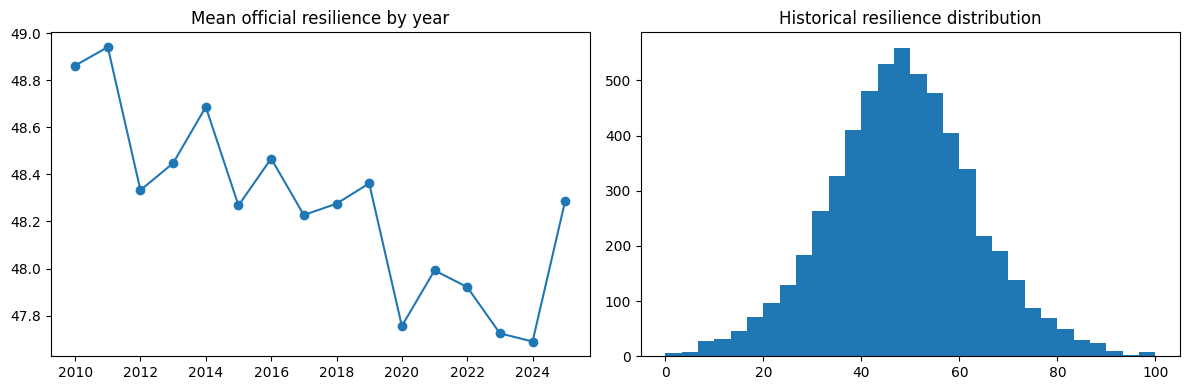

In [9]:
target_summary = labels.groupby('year')[TARGET].agg(['count', 'mean', 'std', 'min', 'max'])
assert target_summary['count'].eq(EXPECTED_REGIONS).all()
display(target_summary)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(target_summary.index, target_summary['mean'], marker='o')
ax[0].set_title('Mean official resilience by year')
ax[1].hist(labels[TARGET], bins=30)
ax[1].set_title('Historical resilience distribution')
plt.tight_layout()
plt.show()

## Predictor Missingness and 2026 Support

Missingness is compared across years, including the unavailable 2026 post-harvest assessment. Other 2026 values must be present wherever used at inference.

,climate,agriculture,economy,logistics,social_nutrition,shock_history,auxiliary_indicators,post_harvest_assessment
year,,,,,,,,
2022,0.004655,0.008729,0.006983,0.005587,0.014277,0.0,0.0,0.0
2023,0.004423,0.007332,0.004539,0.003724,0.010863,0.0,0.0,0.0
2024,0.001862,0.006983,0.003142,0.004655,0.011173,0.0,0.0,0.0
2025,0.003026,0.006983,0.003142,0.003259,0.012104,0.0,0.0,0.0
2026,0.004655,0.006285,0.005237,0.006518,0.012415,0.0,0.0,1.0


,table,historical_missing_pct,missing_2026_pct
0,climate,0.545566,0.465549
1,agriculture,1.191515,0.628492
2,economy,0.739787,0.523743
3,logistics,0.535382,0.651769
4,social_nutrition,1.699255,1.241465
5,shock_history,0.000000,0.000000
6,auxiliary_indicators,0.000000,0.000000
7,post_harvest_assessment,0.000000,100.000000


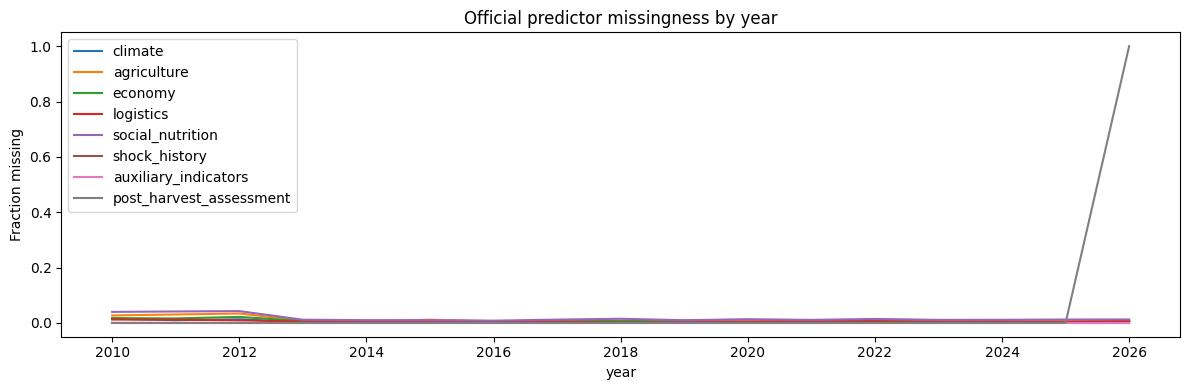

In [10]:
missingness_by_year = pd.DataFrame({
    name: annual[name].set_index(['year', 'region_id']).isna().groupby(level='year').mean().mean(axis=1)
    for name in ANNUAL
})
covariate_shift = pd.DataFrame([
    {'table': name, 'historical_missing_pct': 100 * annual[name].loc[
        annual[name].year.lt(TARGET_YEAR)].drop(columns=['region_id', 'year']).isna().mean().mean(),
     'missing_2026_pct': 100 * annual[name].loc[
         annual[name].year.eq(TARGET_YEAR)].drop(columns=['region_id', 'year']).isna().mean().mean()}
    for name in ANNUAL
])
assert annual['post_harvest_assessment'].loc[
    annual['post_harvest_assessment'].year.eq(TARGET_YEAR),
    'post_harvest_assessment_score'].isna().all()
display(missingness_by_year.tail())
display(covariate_shift)
ax = missingness_by_year.plot(figsize=(12, 4), title='Official predictor missingness by year')
ax.set_ylabel('Fraction missing')
plt.tight_layout()
plt.show()

#### Insights

> Data coverage and 2026 availability are checked before feature construction. Missing post-harvest observations are not filled with the true future score.

---

# Preprocessing <a name="5"></a>

---

No full-panel scaler, discretization, or outcome-based imputation is fitted. CatBoost consumes numeric missing values natively and categorical strings are handled in the frozen model adapter.

In [11]:
preprocessing_decisions = pd.DataFrame([
    {'component': 'annual numeric values', 'policy': 'native CatBoost NaN; no global fit'},
    {'component': 'categorical values', 'policy': 'string categories in cb_frame'},
    {'component': 'current-year post-harvest', 'policy': 'exclude from both resilience models'},
    {'component': 'target and neighbor history', 'policy': 'shift by one year before aggregation'},
    {'component': 'predictions', 'policy': 'no manual correction or clipping'},
])
preprocessing_decisions.to_csv(RESULTS_DIR / 'preprocessing_decisions.csv', index=False)
display(preprocessing_decisions)

,component,policy
0,annual numeric values,native CatBoost NaN; no global fit
1,categorical values,string categories in cb_frame
2,current-year post-harvest,exclude from both resilience models
3,target and neighbor history,shift by one year before aggregation
4,predictions,no manual correction or clipping


#### Insights

> The two models share the same preprocessing. The challenger adds only one forward-predicted proxy feature.

---

# Temporal Target Feature Engineering <a name="6"></a>

---

Own target and post-harvest histories use `shift(1)` before rolling or expanding. Labels from the validation year cannot enter that year’s features.

In [12]:
t0 = time.time()

panel = build_frozen_panel(labels)
assert len(panel) == EXPECTED_PANEL_ROWS and not panel.duplicated(['region_id', 'year']).any()
supervised = panel.merge(labels, on=['region_id', 'year'], how='inner', validate='one_to_one')
supervised = supervised[supervised.year.between(HISTORY_START, 2025)].reset_index(drop=True)
test2026 = sample[['region_id']].merge(panel[panel.year.eq(TARGET_YEAR)], on='region_id', how='left', validate='one_to_one', sort=False)

# Keys, row identities and chronology.
assert len(supervised) == EXPECTED_REGIONS * 13 and supervised.year.min() == HISTORY_START and supervised.year.max() == 2025
assert len(test2026) == EXPECTED_REGIONS and test2026.region_id.tolist() == sample.region_id.tolist(), 'test rows must follow sample order'
assert panel.loc[panel.year.eq(TARGET_YEAR), RAW_TARGET].isna().all(), '2026 target must not exist'
assert panel.loc[panel.year.eq(TARGET_YEAR), PH_COL].isna().all(), 'PH is unavailable in 2026'
assert test2026.nb_thm.notna().all() and supervised.nb_thm.notna().all()
row = panel[(panel.region_id == sample.region_id.iloc[0]) & (panel.year == 2015)].iloc[0]
yh = labels[labels.region_id == sample.region_id.iloc[0]].set_index('year')[TARGET].sort_index()
assert np.isclose(row.target_lag1, yh.loc[2014]) and np.isclose(row.target_lag2, yh.loc[2013])
assert np.isclose(row.target_history_mean, yh.loc[:2014].mean())

# No future-label access: overwrite every label from 2020 on; every history feature for years <= 2020 must be unchanged.
lab_perturbed = labels.copy()
lab_perturbed.loc[lab_perturbed.year >= 2020, TARGET] = -1e6
panel_p = build_frozen_panel(lab_perturbed)
HIST_COLS = ['target_lag1', 'target_lag2', 'target_roll2', 'target_roll3', 'target_history_mean', 'target_delta1', 'nb_thm']
m_old = panel.year <= 2020
for c in HIST_COLS:
    assert np.allclose(panel.loc[m_old, c].to_numpy(float), panel_p.loc[m_old, c].to_numpy(float), equal_nan=True), f'leak in {c}'
del panel_p, lab_perturbed; gc.collect()

# Label-free regime covariates (labels <= t-1 only). Used ONLY by the validation gates and EDA, never as model features.
P = panel.sort_values(['region_id', 'year']).copy()
gp = P.groupby('region_id')[RAW_TARGET]
P['d1'] = gp.diff()
P['vol'] = gp.transform(lambda s: s.shift(1).expanding(min_periods=2).std())
P['absgap'] = (P.nb_thm - P.target_history_mean).abs()
P['absdev1'] = (P.target_lag1 - P.target_history_mean).abs()
P['h'] = P.year - 2010


def years_since_largest_shock(s):
    out, best, tb = [], -1.0, None
    for i, v in enumerate(s.shift(1).to_numpy()):
        if not np.isnan(v) and abs(v) > best:
            best, tb = abs(v), i
        out.append(np.nan if tb is None else i - tb)
    return pd.Series(out, index=s.index)


P['since'] = P.groupby('region_id').d1.transform(years_since_largest_shock)
NUM_CURRENT = [c for c in panel.columns if c.split('.')[0] in BLOCKS and c not in GLOBAL_FLAGS]
_z = []
for c in NUM_CURRENT:
    m_ = P.groupby('region_id')[c].transform(lambda s: s.shift(1).expanding(min_periods=2).mean())
    s_ = P.groupby('region_id')[c].transform(lambda s: s.shift(1).expanding(min_periods=2).std())
    _z.append(((P[c] - m_) / s_.replace(0, np.nan)).abs())
P['drift'] = pd.concat(_z, axis=1).clip(upper=10).mean(axis=1)
P['shock_now'] = P['shock_history.shock_event']
REGIME = P[['region_id', 'year', 'h', 'since', 'vol', 'absgap', 'absdev1', 'target_history_mean', 'shock_now', 'drift']].copy()
del _z; gc.collect()
assert REGIME[REGIME.year.between(2018, 2026)][['since', 'vol', 'absgap', 'absdev1']].notna().all().all()

#### Insights

> The historical target is used only through year t-1; the 2026 target and current post-harvest assessment remain missing.

---

# Spatial Neighbor Feature Engineering <a name="7"></a>

---

The official graph supplies the weighted neighbor mean of historical target levels. The current target and same-year post-harvest score never enter this spatial feature.

In [13]:
assert GRAPH.region_id.isin(sample.region_id).all()
assert panel.loc[panel.year.eq(TARGET_YEAR), 'nb_thm'].notna().all()
display(pd.DataFrame({'feature': ['nb_thm'], 'source': ['neighbor target histories through t-1'],
                      'count_2026': [int(test2026.nb_thm.notna().sum())]}))

,feature,source,count_2026
0,nb_thm,neighbor target histories through t-1,358


#### Insights

> Spatial level information is a legal historical prior. No external geographic data or 2026 target values are used.

---

# Feature Audit <a name="8"></a>

---

The 61-feature F_N contract is checked against V25 before training. A second EDA pass quantifies the historical target, spatial level, and covariate-regime structure used to judge 2026 transfer.

In [14]:
FROZEN_FN = ['region_id', 'year', 'climate.rainfall_mm', 'climate.temperature_c', 'climate.drought_index', 'climate.flood_frequency',
             'climate.climate_anomaly_index', 'climate.heatwave_days', 'climate.extreme_rain_days', 'agriculture.irrigation_coverage_pct',
             'agriculture.fertilizer_use_index', 'agriculture.farm_mechanization_index', 'agriculture.seed_resilience_index',
             'agriculture.crop_diversity_index', 'agriculture.rice_yield_ton_ha', 'agriculture.maize_yield_ton_ha',
             'agriculture.production_stability_score', 'economy.gdp_per_capita_usd', 'economy.poverty_rate_pct', 'economy.unemployment_rate_pct',
             'economy.food_cpi_index', 'economy.fuel_price_index', 'economy.import_dependency_ratio', 'economy.exchange_rate_pressure_index',
             'economy.remittance_dependency_ratio', 'logistics.road_density_index', 'logistics.port_access_score',
             'logistics.cold_storage_capacity_index', 'logistics.market_access_score', 'logistics.logistics_disruption_index',
             'logistics.travel_time_to_main_market_min', 'social_nutrition.hdi', 'social_nutrition.internet_penetration_pct',
             'social_nutrition.social_protection_coverage', 'social_nutrition.stunting_rate_pct', 'social_nutrition.calorie_adequacy_index',
             'social_nutrition.food_expenditure_share_pct', 'social_nutrition.governance_effectiveness_score',
             'social_nutrition.food_early_warning_capacity', 'social_nutrition.public_health_capacity_score', 'shock_history.shock_event',
             'auxiliary_indicators.satellite_composite_index', 'auxiliary_indicators.mobile_connectivity_index',
             'auxiliary_indicators.survey_response_latency', 'auxiliary_indicators.administrative_code_score', 'country', 'climate_zone',
             'is_capital_or_major_urban', 'coastal_exposure', 'ph_lag1', 'ph_roll3', 'ph_roll5', 'ph_history_mean', 'ph_delta',
             'target_lag1', 'target_lag2', 'target_roll2', 'target_roll3', 'target_history_mean', 'target_delta1', 'nb_thm']
FROZEN_FN_SHA256 = '76c6c261'   # prefix of sha256('|'.join(F_N)) recorded by V22/V24
EXCLUDE = {'admin_level_1', PH_COL, TARGET, RAW_TARGET, *GLOBAL_FLAGS}
F_N = [c for c in panel.columns if c not in EXCLUDE]
assert F_N == FROZEN_FN, 'derived feature list differs from the frozen V22 F_N contract'
FEATURE_HASH = hashlib.sha256('|'.join(F_N).encode()).hexdigest()
assert FEATURE_HASH.startswith(FROZEN_FN_SHA256), f'F_N hash {FEATURE_HASH[:16]} != V22 contract {FROZEN_FN_SHA256}'
FEATURES = F_N


def cb_frame(df, features=FEATURES):
    x = df[features].copy()
    for c in CAT_COLS:
        if c in features:
            x[c] = x[c].astype(str)
    return x


def make_cb(iterations, seed):
    extra = dict(task_type='GPU', devices='0') if CB_DEVICE == 'GPU' else dict(task_type='CPU', thread_count=THREADS)
    return CatBoostRegressor(loss_function='RMSE', eval_metric='RMSE', iterations=int(iterations), depth=CB_CFG['depth'],
                             learning_rate=CB_CFG['learning_rate'], l2_leaf_reg=CB_CFG['l2_leaf_reg'], random_seed=int(seed),
                             boosting_type='Ordered', allow_writing_files=False, verbose=False, **extra)


def _fit(model, *args, **kw):
    global CB_DEVICE
    try:
        return model.fit(*args, **kw)
    except Exception as e:                         # GPU opt-in only: fall back to the frozen CPU path
        if CB_DEVICE != 'GPU':
            raise
        print('GPU CatBoost failed -> CPU fallback:', str(e)[:120]); CB_DEVICE = 'CPU'
        return None


def cb_select_iterations(tr, va, seed, features=FEATURES):
    m = make_cb(CB_CFG['max_iterations'], seed)
    cats = [c for c in CAT_COLS if c in features]
    if _fit(m, cb_frame(tr, features), tr[TARGET], cat_features=cats, eval_set=(cb_frame(va, features), va[TARGET]),
            use_best_model=True, early_stopping_rounds=CB_CFG['early_stopping_rounds'], verbose=False) is None:
        return cb_select_iterations(tr, va, seed, features)
    it, best = int(m.tree_count_), float(m.get_best_score()['validation']['RMSE'])
    del m; gc.collect()
    return it, best


def cb_fit_fixed(tr, iterations, seed, features=FEATURES):
    m = make_cb(iterations, seed)
    if _fit(m, cb_frame(tr, features), tr[TARGET], cat_features=[c for c in CAT_COLS if c in features], verbose=False) is None:
        return cb_fit_fixed(tr, iterations, seed, features)
    return m

## Frozen Feature Contract

Feature order, hash, missingness, and causal lineage are recorded; no feature is selected using 2026 outcomes.

In [15]:
REJECTED = {'nb_thm_local', 'nb_cty_rel', 'hist_vol', 'since_shock', 'since', 'max_shock', 'ewm01', 'ewm05', 'ewm03', 'target_roll5',
            'gxv', 'vol', 'absgap', 'absdev1', 'drift', 'admin_level_1', PH_COL, RAW_TARGET, TARGET, *GLOBAL_FLAGS}
assert len(FEATURES) == 61 and len(set(FEATURES)) == 61 and FEATURES[-1] == 'nb_thm'
assert not (REJECTED & set(FEATURES)), 'a rejected feature re-entered the feature matrix'
ANNUAL_FIELDS = [c for c in FEATURES if c.split('.')[0] in BLOCKS]
F_H = [c for c in FEATURES if c not in ANNUAL_FIELDS]
assert len(ANNUAL_FIELDS) == 43 and len(F_H) == 18 and set(CAT_COLS) <= set(F_H) and 'nb_thm' in F_H
F_H_HASH = hashlib.sha256('|'.join(F_H).encode()).hexdigest()
pd.DataFrame({'feature': FEATURES, 'in_F_H': [c in F_H for c in FEATURES]}).to_csv(RESULTS_DIR / 'feature_manifest_FN.csv', index=False)
(RESULTS_DIR / 'feature_contract.json').write_text(json.dumps({'incumbent': 'F_N (V22)', 'n_features': len(FEATURES), 'sha256': FEATURE_HASH,
                                                             'robustness': 'F_H = F_N minus 43 annual fields', 'n_features_F_H': len(F_H),
                                                             'sha256_F_H': F_H_HASH, 'F_H': F_H}, indent=2))
print('F_N features:', len(FEATURES), '| sha256', FEATURE_HASH[:16], '| F_H features:', len(F_H))

F_N features: 61 | sha256 76c6c261edba8197 | F_H features: 18


In [16]:
lab_idx = labels.set_index(['region_id', 'year'])[TARGET]
chk = supervised.sample(40, random_state=25)
for r in chk.itertuples():
    past = lab_idx.loc[r.region_id].loc[:r.year - 1]
    assert np.isclose(r.target_lag1, past.iloc[-1]) and np.isclose(r.target_history_mean, past.mean())
    assert np.isclose(r.target_roll3, past.iloc[-3:].mean()) and np.isclose(r.target_delta1, past.iloc[-1] - past.iloc[-2])
    e = GRAPH[GRAPH.region_id == r.region_id]
    thm_nb = [lab_idx.loc[n].loc[:r.year - 1].mean() for n in e.neighbor_region_id]
    assert np.isclose(r.nb_thm, np.average(thm_nb, weights=e.neighbor_weight)), 'nb_thm mismatch'
creation = pd.DataFrame([['target_lag1/lag2/roll2/roll3/history_mean/delta1', 'labels <= t-1', 'KEEP (frozen)'],
                         ['ph_lag1/roll3/roll5/history_mean/delta', 'PH <= t-1', 'KEEP (frozen)'],
                         ['nb_thm', 'official graph, neighbours target_history_mean <= t-1', 'KEEP (frozen)'],
                         ['nb_thm_local / gap x vol / shock recency / residual corrections / V25 diagnostics', '-', 'NOT CREATED']],
                        columns=['feature', 'causal source', 'status'])
creation.to_csv(RESULTS_DIR / 'feature_creation_report.csv', index=False); display(creation)
print('independent re-derivation of target histories and nb_thm on 40 sampled rows: OK')

,feature,causal source,status
0,target_lag1/lag2/roll2/roll3/history_mean/delta1,labels <= t-1,KEEP (frozen)
1,ph_lag1/roll3/roll5/history_mean/delta,PH <= t-1,KEEP (frozen)
2,nb_thm,"official graph, neighbours target_history_mean...",KEEP (frozen)
3,nb_thm_local / gap x vol / shock recency / res...,-,NOT CREATED


independent re-derivation of target histories and nb_thm on 40 sampled rows: OK


## Target Dynamics and 2026 Regime

V25’s established label and covariate diagnostics are recomputed on the active official files. They support interpretation and do not enter the candidate feature matrices.

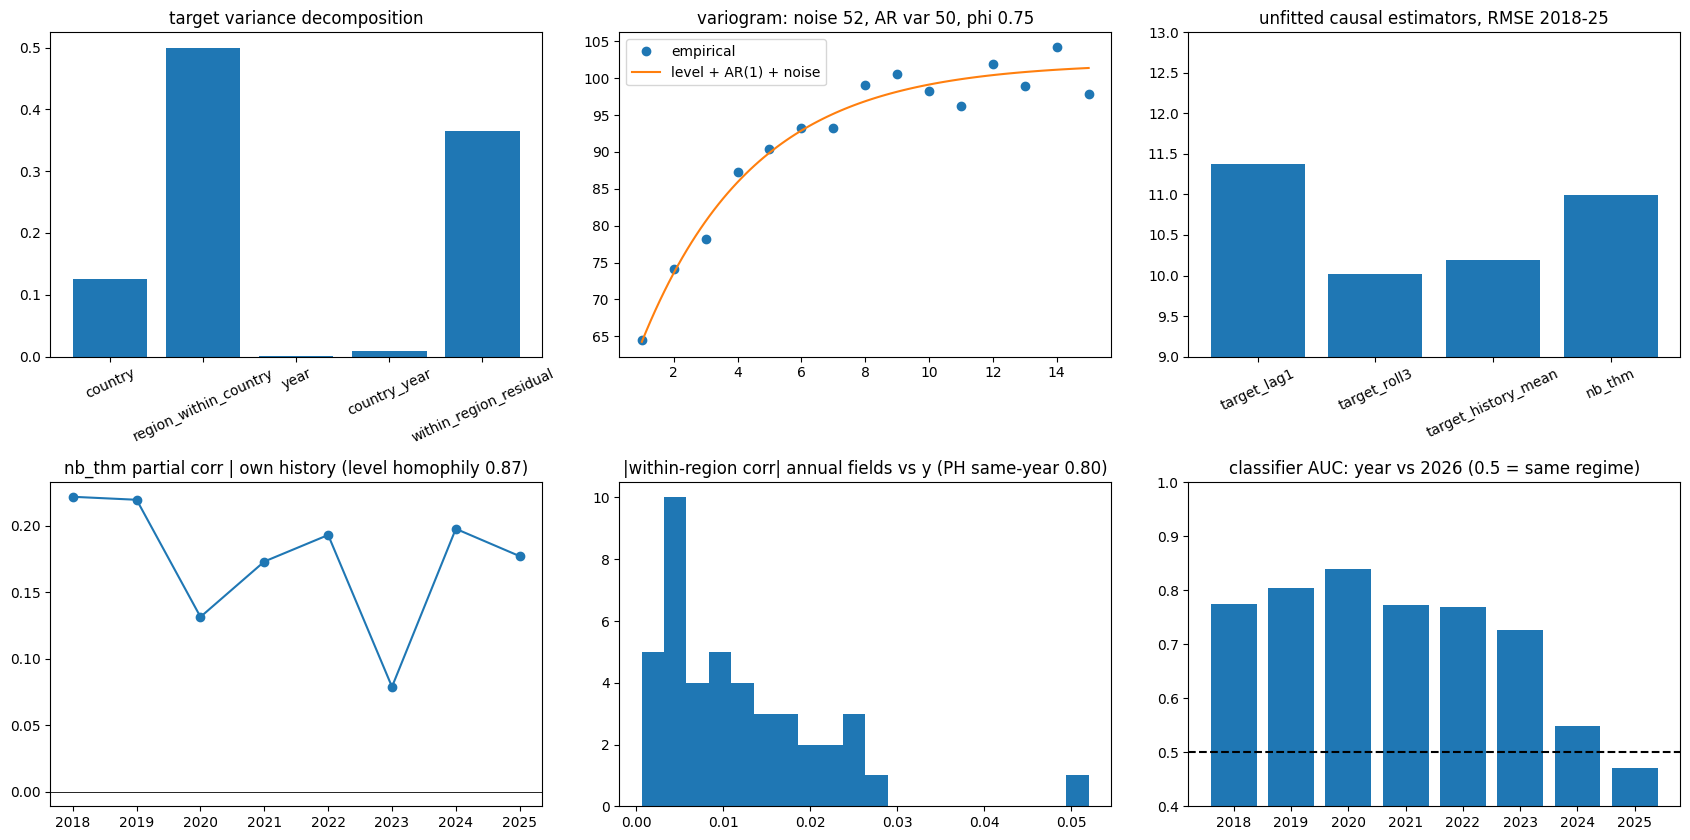

{
  "variance_decomposition": {
    "country": 0.1259308283960873,
    "region_within_country": 0.49957402525522415,
    "year": 0.0006044815126627989,
    "country_year": 0.009051362574907497,
    "within_region_residual": 0.36483930226111827
  },
  "variogram_fit_level_ar1_noise": {
    "sigma2_noise": 51.8821297682513,
    "ar1_var": 50.233035787998034,
    "phi": 0.7536793197379273
  },
  "unfitted_estimator_rmse_2018_2025": {
    "target_lag1": 11.369954054792858,
    "target_roll3": 10.018487546425213,
    "target_history_mean": 10.193514991372076,
    "nb_thm": 10.98942294882948
  },
  "graph_level_homophily": 0.8700698232043619,
  "nb_thm_partial_corr_given_own_history": {
    "2018": 0.2217563807161387,
    "2019": 0.2195058251435126,
    "2020": 0.13136681129635144,
    "2021": 0.17305278510489278,
    "2022": 0.19300586659727478,
    "2023": 0.07877592743214853,
    "2024": 0.1976517351955068,
    "2025": 0.17709792836024607
  },
  "max_abs_within_region_annual_field_corr": 

In [17]:
META = metadata.set_index('region_id')
L = labels.merge(metadata[['region_id', 'country']], on='region_id')
Y_WIDE = labels.pivot(index='region_id', columns='year', values=TARGET).sort_index()      # 358 x 2010..2025 (complete)
assert Y_WIDE.notna().all().all() and list(Y_WIDE.columns) == list(range(2010, 2026))
REG = Y_WIDE.index.to_numpy()
CTY = META.country.reindex(REG)

# 1. variance decomposition
g0 = L[TARGET].mean(); cm = L.groupby('country')[TARGET].transform('mean'); rm = L.groupby('region_id')[TARGET].transform('mean')
ym = L.groupby('year')[TARGET].transform('mean'); cym = L.groupby(['country', 'year'])[TARGET].transform('mean')
tot = ((L[TARGET] - g0) ** 2).sum()
vdec = {'country': ((cm - g0) ** 2).sum() / tot, 'region_within_country': ((rm - cm) ** 2).sum() / tot, 'year': ((ym - g0) ** 2).sum() / tot,
        'country_year': ((cym - cm - ym + g0) ** 2).sum() / tot}
vdec['within_region_residual'] = 1 - sum(vdec.values())


# 2. variogram (country-year path removed) and the level + AR(1) + noise fit (same estimator as the Kalman benchmark)
def variogram(Yh):
    A = (Yh - Yh.groupby(CTY.values).transform('mean')).to_numpy()
    ks = np.arange(1, A.shape[1]); gs = np.array([0.5 * np.mean((A[:, k:] - A[:, :-k]) ** 2) for k in ks])
    ns = np.array([A[:, k:].size for k in ks], float)
    return ks, gs, ns


def variogram_params(Yh):
    ks, gs, ns = variogram(Yh)
    f = lambda p: (p[0] + p[1] * (1 - p[2] ** ks) - gs) * np.sqrt(ns / ns.max())
    return optimize.least_squares(f, [50, 50, 0.75], bounds=([1, 0, 0], [500, 500, 0.99])).x


ks, gs, ns = variogram(Y_WIDE)
s2_all, a2_all, phi_all = variogram_params(Y_WIDE)

# 3. own history vs target: unfitted causal estimators on 2018-2025
E = P[P.year.isin(OUTER_YEARS)]
E_y = E[RAW_TARGET]
unfitted = {c: rmse(E_y, E[c]) for c in ['target_lag1', 'target_roll3', 'target_history_mean', 'nb_thm']}


# 4. graph level signal
def partial_corr(d, v, ctrl):
    X = np.column_stack([np.ones(len(d))] + [d[c] for c in ctrl])
    ry = d[RAW_TARGET] - X @ np.linalg.lstsq(X, d[RAW_TARGET], rcond=None)[0]
    rv = d[v] - X @ np.linalg.lstsq(X, d[v], rcond=None)[0]
    return float(np.corrcoef(ry, rv)[0, 1])


W_GRAPH = np.zeros((len(REG), len(REG)))
_ri = {r: i for i, r in enumerate(REG)}
for r, n_, w_ in GRAPH[['region_id', 'neighbor_region_id', 'neighbor_weight']].itertuples(index=False):
    W_GRAPH[_ri[r], _ri[n_]] = w_
W_GRAPH = W_GRAPH / W_GRAPH.sum(1, keepdims=True)
lvl = Y_WIDE.mean(1).to_numpy()
homophily = float(np.corrcoef(lvl, W_GRAPH @ lvl)[0, 1])
nb_pc = {int(y): partial_corr(d, 'nb_thm', ['target_history_mean', 'target_roll3']) for y, d in E.groupby('year')}

# 5. within-region annual-field signal and PH relationship
S_ = P[P.year.between(2013, 2025)]
yw = S_[RAW_TARGET] - S_.groupby('region_id')[RAW_TARGET].transform('mean')
within = {c: float(np.corrcoef((S_[c] - S_.groupby('region_id')[c].transform('mean')).fillna(0), yw)[0, 1]) for c in NUM_CURRENT}
Hh = P[P.year.le(2025)]
phw = Hh[PH_COL] - Hh.groupby('region_id')[PH_COL].transform('mean'); tw = Hh[RAW_TARGET] - Hh.groupby('region_id')[RAW_TARGET].transform('mean')
ph_same = float(np.corrcoef(phw, tw)[0, 1])
ph_lag = float(pd.concat([tw, phw.groupby(Hh.region_id).shift(1)], axis=1).dropna().corr().iloc[0, 1])

# 6. 2024/2025 similarity to 2026 (label-free covariates; classifier AUC, 0.5 = indistinguishable)
SIM_COV = ['since', 'vol', 'absgap', 'absdev1', 'target_history_mean', 'shock_now', 'drift']
R26 = sample[['region_id']].merge(REGIME[REGIME.year.eq(TARGET_YEAR)], on='region_id', how='left')


def auc_vs_2026(A, cols):
    X = pd.concat([A[cols], R26[cols]]).fillna(0).to_numpy(); yb = np.r_[np.zeros(len(A)), np.ones(len(R26))]
    X = StandardScaler().fit_transform(X); pr = np.zeros(len(yb))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, yb):
        pr[te] = LogisticRegression(C=0.3, max_iter=2000).fit(X[tr], yb[tr]).predict_proba(X[te])[:, 1]
    return float(roc_auc_score(yb, pr))


year_auc = {int(t): auc_vs_2026(REGIME[REGIME.year.eq(t)], SIM_COV) for t in OUTER_YEARS}
bins, blab = [-1, 0, 1, 3, 6, 50], ['0', '1', '2-3', '4-6', '7+']
since_hist = pd.cut(REGIME[REGIME.year.isin(OUTER_YEARS)].since, bins, labels=blab).value_counts(normalize=True).sort_index()
since_2026 = pd.cut(R26.since, bins, labels=blab).value_counts(normalize=True).sort_index()
hist_rng = P[P.year.le(2025)].groupby('region_id')[NUM_CURRENT].agg(['min', 'max'])
t26 = P[P.year.eq(TARGET_YEAR)].set_index('region_id')[NUM_CURRENT]
outside = {c: float(((t26[c] < hist_rng[(c, 'min')]) | (t26[c] > hist_rng[(c, 'max')])).mean()) for c in NUM_CURRENT}

eda_summary = {'variance_decomposition': vdec, 'variogram_fit_level_ar1_noise': {'sigma2_noise': s2_all, 'ar1_var': a2_all, 'phi': phi_all},
               'unfitted_estimator_rmse_2018_2025': unfitted, 'graph_level_homophily': homophily,
               'nb_thm_partial_corr_given_own_history': nb_pc, 'max_abs_within_region_annual_field_corr': float(np.nanmax(np.abs(list(within.values())))),
               'ph_within_corr_same_year': ph_same, 'ph_within_corr_lag1': ph_lag, 'year_auc_vs_2026': year_auc,
               'since_shock_share_2018_2025': since_hist.round(3).to_dict(), 'since_shock_share_2026': since_2026.round(3).to_dict(),
               'annual_fields_2026_share_outside_own_range_top5': dict(sorted(outside.items(), key=lambda kv: -kv[1])[:5])}
(RESULTS_DIR / 'eda_summary.json').write_text(json.dumps(eda_summary, indent=2, default=float))

fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
ax[0, 0].bar(list(vdec), list(vdec.values())); ax[0, 0].tick_params(axis='x', rotation=25); ax[0, 0].set_title('target variance decomposition')
kk = np.linspace(1, ks.max(), 100)
ax[0, 1].plot(ks, gs, 'o', label='empirical'); ax[0, 1].plot(kk, s2_all + a2_all * (1 - phi_all ** kk), label='level + AR(1) + noise')
ax[0, 1].legend(); ax[0, 1].set_title(f'variogram: noise {s2_all:.0f}, AR var {a2_all:.0f}, phi {phi_all:.2f}')
ax[0, 2].bar(list(unfitted), list(unfitted.values())); ax[0, 2].set_ylim(9, 13); ax[0, 2].tick_params(axis='x', rotation=25); ax[0, 2].set_title('unfitted causal estimators, RMSE 2018-25')
ax[1, 0].plot(list(nb_pc), list(nb_pc.values()), 'o-'); ax[1, 0].axhline(0, c='k', lw=.6); ax[1, 0].set_title(f'nb_thm partial corr | own history (level homophily {homophily:.2f})')
ax[1, 1].hist(np.abs(list(within.values())), bins=20); ax[1, 1].set_title(f'|within-region corr| annual fields vs y (PH same-year {ph_same:.2f})')
ax[1, 2].bar([str(y) for y in year_auc], list(year_auc.values())); ax[1, 2].axhline(.5, c='k', ls='--'); ax[1, 2].set_ylim(.4, 1)
ax[1, 2].set_title('classifier AUC: year vs 2026 (0.5 = same regime)')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'eda_overview.png', dpi=110); plt.show()
print(json.dumps(eda_summary, indent=2, default=float))

#### Insights

> The year-similarity check is label-free; the same historical target years remain the only source of training labels.

---

# Post-Harvest Proxy Engineering <a name="9"></a>

---

A separate CatBoost is fitted for each target year. Every proxy prediction for year t is generated from observed post-harvest scores in years strictly before t.

## Proxy Input Contract

The proxy can use only the frozen F_N predictors. In particular, current-year post-harvest and resilience targets are excluded by assertion.

In [18]:
PROXY_FEATURES = FEATURES.copy()
assert PH_COL not in PROXY_FEATURES and TARGET not in PROXY_FEATURES
assert RAW_TARGET not in PROXY_FEATURES and CFG.PROXY_FEATURE not in PROXY_FEATURES
assert len(PROXY_FEATURES) == 61
assert panel.loc[panel.year.eq(TARGET_YEAR), PH_COL].isna().all()
print('Proxy inputs:', len(PROXY_FEATURES), '| no current outcome columns')

Proxy inputs: 61 | no current outcome columns


## Forward Out-of-Fold Proxy

The training rows receive predictions from earlier years only. The first supervised year is 2013, when prior observations are already available.

In [19]:
proxy_parts = []
proxy_audit = []
for predict_year in range(HISTORY_START, TARGET_YEAR + 1):
    train = panel.loc[(panel.year < predict_year) & panel[PH_COL].notna()]
    valid = panel.loc[panel.year.eq(predict_year)]
    assert len(train) and train.year.max() < predict_year
    assert len(valid) == EXPECTED_REGIONS
    model = CatBoostRegressor(
        loss_function='RMSE', iterations=CFG.PROXY_ITERATIONS,
        depth=CFG.PROXY_DEPTH, learning_rate=CFG.PROXY_LEARNING_RATE,
        l2_leaf_reg=CFG.PROXY_L2, random_seed=CFG.PROXY_SEED,
        task_type='CPU', thread_count=THREADS, allow_writing_files=False, verbose=False,
    )
    model.fit(cb_frame(train, PROXY_FEATURES), train[PH_COL], cat_features=CAT_COLS)
    pred = model.predict(cb_frame(valid, PROXY_FEATURES))
    proxy_parts.append(pd.DataFrame({'region_id': valid.region_id.to_numpy(),
                                     'year': valid.year.to_numpy(), CFG.PROXY_FEATURE: pred}))
    observed = valid[PH_COL].notna().to_numpy()
    proxy_audit.append({'predict_year': predict_year, 'proxy_fit_max_year': int(train.year.max()),
                        'proxy_train_rows': len(train),
                        'proxy_rmse': rmse(valid.loc[observed, PH_COL], pred[observed])
                        if observed.any() else np.nan})
    print('Forward proxy:', predict_year, '| trained through', int(train.year.max()))
    del model

proxy_panel = pd.concat(proxy_parts, ignore_index=True)
proxy_scores = pd.DataFrame(proxy_audit)
assert (proxy_scores.proxy_fit_max_year < proxy_scores.predict_year).all()
assert not proxy_panel.duplicated(['region_id', 'year']).any()
assert np.isfinite(proxy_panel[CFG.PROXY_FEATURE]).all()
display(proxy_scores)

Forward proxy: 2013 | trained through 2012
Forward proxy: 2014 | trained through 2013
Forward proxy: 2015 | trained through 2014
Forward proxy: 2016 | trained through 2015
Forward proxy: 2017 | trained through 2016
Forward proxy: 2018 | trained through 2017
Forward proxy: 2019 | trained through 2018
Forward proxy: 2020 | trained through 2019
Forward proxy: 2021 | trained through 2020
Forward proxy: 2022 | trained through 2021
Forward proxy: 2023 | trained through 2022
Forward proxy: 2024 | trained through 2023
Forward proxy: 2025 | trained through 2024
Forward proxy: 2026 | trained through 2025


,predict_year,proxy_fit_max_year,proxy_train_rows,proxy_rmse
0,2013,2012,1074,11.993362
1,2014,2013,1432,11.889691
2,2015,2014,1790,12.439016
3,2016,2015,2148,11.503473
4,2017,2016,2506,12.013322
5,2018,2017,2864,11.729465
6,2019,2018,3222,11.965879
7,2020,2019,3580,12.752471
8,2021,2020,3938,12.023545
9,2022,2021,4296,11.242491


#### Insights

> A good proxy RMSE is only a diagnostic. The proxy is retained only if it improves the downstream resilience forecasts on comparable folds.

---

# Walk-Forward Validation Design <a name="10"></a>

---

Each outer year 2018-2025 trains only on preceding years. The inner year t-1 selects tree count, after which each model is refitted through t-1 and predicts t.

In [20]:
with_proxy = supervised.merge(proxy_panel, on=['region_id', 'year'], how='left', validate='one_to_one')
test_proxy = test2026.merge(proxy_panel, on=['region_id', 'year'], how='left', validate='one_to_one', sort=False)
assert with_proxy[CFG.PROXY_FEATURE].notna().all() and test_proxy[CFG.PROXY_FEATURE].notna().all()
assert test_proxy.region_id.tolist() == sample.region_id.tolist()
assert all(proxy_scores.loc[proxy_scores.predict_year.eq(t), 'proxy_fit_max_year'].iloc[0] < t
           for t in OUTER_YEARS + [TARGET_YEAR])
folds = pd.DataFrame([{'predict_year': t, 'inner_train_end': t - 2,
                       'inner_selection_year': t - 1, 'outer_train_end': t - 1}
                      for t in OUTER_YEARS + [TARGET_YEAR]])
display(folds)

,predict_year,inner_train_end,inner_selection_year,outer_train_end
0,2018,2016,2017,2017
1,2019,2017,2018,2018
2,2020,2018,2019,2019
3,2021,2019,2020,2020
4,2022,2020,2021,2021
5,2023,2021,2022,2022
6,2024,2022,2023,2023
7,2025,2023,2024,2024
8,2026,2024,2025,2025


#### Insights

> Both candidates share identical validation years, historical labels, inner iteration selection, and seed averaging.

---

# Temporal Baseline Diagnostics <a name="11"></a>

---

A simple previous-year target forecast supplies a model-free reference on the same outer validation rows.

In [21]:
baseline = supervised.loc[supervised.year.isin(OUTER_YEARS)].copy()
baseline_scores = baseline.groupby('year').apply(
    lambda fold: rmse(fold[TARGET], fold.target_lag1), include_groups=False
).rename('lag1_rmse').reset_index()
display(baseline_scores)

,year,lag1_rmse
0,2018,11.693969
1,2019,11.068143
2,2020,11.713873
3,2021,11.669722
4,2022,10.410077
5,2023,10.674453
6,2024,12.015629
7,2025,11.613265


#### Insights

> Historical RMSE is shown per year, not replaced by a single favorable year or a Public score.

---

# Modeling <a name="12"></a>

---

The frozen V25/V22 five-seed CatBoost is evaluated alongside an identical learner with one additional proxy input. No pretrained weights are involved.

In [22]:
VARIANTS = {'incumbent': FEATURES, 'proxy_catboost': FEATURES + [CFG.PROXY_FEATURE]}
oof_parts = []
iteration_rows = []
final_predictions = {}
for predict_year in OUTER_YEARS + [TARGET_YEAR]:
    inner_year = predict_year - 1
    inner_train = with_proxy.loc[with_proxy.year.lt(inner_year)]
    inner_valid = with_proxy.loc[with_proxy.year.eq(inner_year)]
    outer_train = with_proxy.loc[with_proxy.year.lt(predict_year)]
    outer_valid = (test_proxy if predict_year == TARGET_YEAR else
                   with_proxy.loc[with_proxy.year.eq(predict_year)])
    assert len(outer_valid) == EXPECTED_REGIONS
    assert inner_train.year.max() < inner_year < predict_year
    assert outer_train.year.max() == predict_year - 1
    for variant, feature_names in VARIANTS.items():
        predictions = []
        for seed in SEEDS:
            iterations, inner_rmse = cb_select_iterations(inner_train, inner_valid, seed, feature_names)
            fitted = cb_fit_fixed(outer_train, iterations, seed, feature_names)
            pred = fitted.predict(cb_frame(outer_valid, feature_names))
            predictions.append(pred)
            iteration_rows.append({'variant': variant, 'year': predict_year, 'seed': seed,
                                   'iterations': iterations, 'inner_rmse': inner_rmse})
            if predict_year != TARGET_YEAR:
                oof_parts.append(pd.DataFrame({'region_id': outer_valid.region_id.to_numpy(),
                                               'year': predict_year, 'y': outer_valid[TARGET].to_numpy(),
                                               'variant': variant, 'seed': seed, 'prediction': pred}))
            del fitted
        if predict_year == TARGET_YEAR:
            final_predictions[variant] = np.mean(predictions, axis=0)
    print('Completed outer year:', predict_year)

oof_per_seed = pd.concat(oof_parts, ignore_index=True)
iteration_log = pd.DataFrame(iteration_rows)
oof = oof_per_seed.groupby(['region_id', 'year', 'variant'], as_index=False).agg(
    y=('y', 'first'), prediction=('prediction', 'mean'))
assert len(oof) == EXPECTED_REGIONS * len(OUTER_YEARS) * len(VARIANTS)
oof_per_seed.to_csv(RESULTS_DIR / 'oof_per_seed.csv', index=False)
oof.to_csv(RESULTS_DIR / 'oof_all_models.csv', index=False)
iteration_log.to_csv(RESULTS_DIR / 'catboost_fold_iterations.csv', index=False)
display(iteration_log.groupby(['variant', 'year'], as_index=False).iterations.mean())

Completed outer year: 2018
Completed outer year: 2019
Completed outer year: 2020
Completed outer year: 2021
Completed outer year: 2022
Completed outer year: 2023
Completed outer year: 2024
Completed outer year: 2025
Completed outer year: 2026


,variant,year,iterations
0,incumbent,2018,241.2
1,incumbent,2019,266.8
2,incumbent,2020,260.6
3,incumbent,2021,217.0
4,incumbent,2022,246.2
5,incumbent,2023,224.8
6,incumbent,2024,474.0
7,incumbent,2025,427.8
8,incumbent,2026,417.6
9,proxy_catboost,2018,218.4


#### Insights

> The challenger differs from the incumbent by exactly one feature. Tree-count selection and final refit follow the same chronological protocol.

---

# Evaluation <a name="13"></a>

---

Pooled OOF RMSE, year-by-year RMSE, the two most deployment-like years, and paired seed results determine the final model. Proxy quality alone is not sufficient.

variant,incumbent,proxy_catboost
year,,
2018,9.090731,9.102036
2019,9.554981,9.527034
2020,9.961135,10.001787
2021,9.318855,9.391429
2022,8.946412,8.909243
2023,9.400988,9.424969
2024,9.497768,9.498068
2025,8.980090,9.000550


,pooled_rmse,recent_rmse,deploy_rmse
variant,,,
incumbent,9.349270,9.295665,9.242554
proxy_catboost,9.362652,9.310447,9.252654


,selected,gates,paired_seed_wins,projected_2026_drmse,projected_ci90,top_5_gain_share,support_matched_dmse,n_eff_2026,similarity_weighted_drmse_report_only,sim_year_auc_report_only,support_covered_2026
0,incumbent,"{'A_deploy_and_seeds': False, 'B_projected_202...",1,0.016661,"[-0.01683113729615293, 0.04956790573571723]",NaN,0.424423,98.444374,0.030461,0.723096,1.0


Paired deployment seed wins: 1 / 5
Selected after historical validation: incumbent


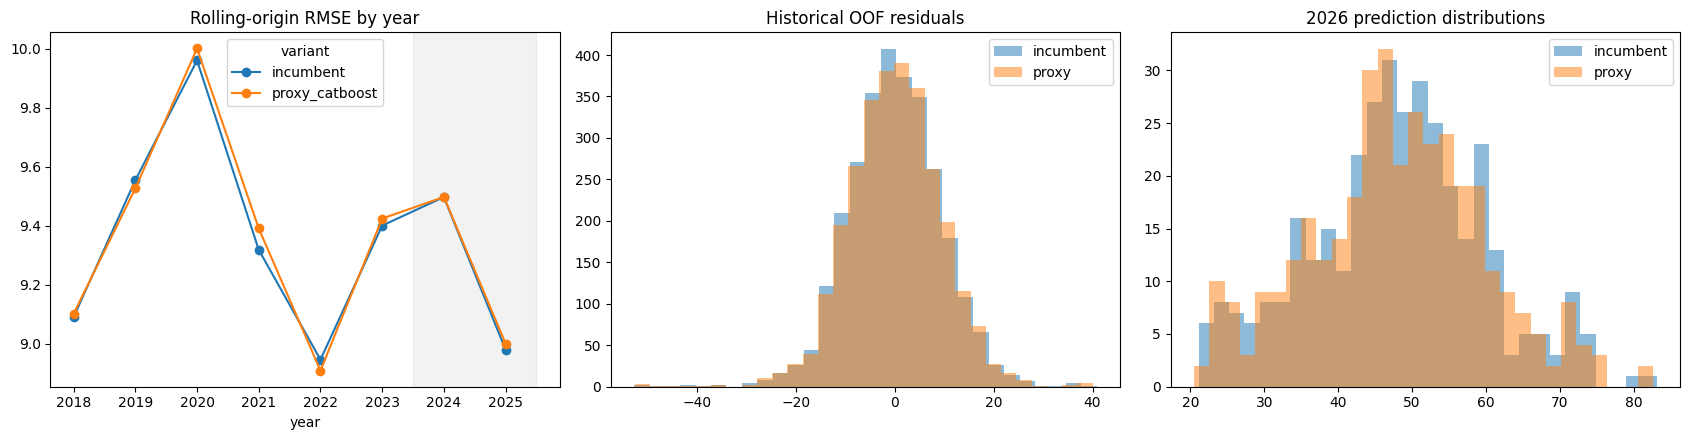

In [23]:
year_scores = oof.groupby(['variant', 'year']).apply(
    lambda frame: rmse(frame.y, frame.prediction), include_groups=False
).rename('rmse').reset_index()
pooled_scores = oof.groupby('variant').apply(
    lambda frame: rmse(frame.y, frame.prediction), include_groups=False
).rename('pooled_rmse')
deploy_scores = oof.loc[oof.year.isin([2024, 2025])].groupby('variant').apply(
    lambda frame: rmse(frame.y, frame.prediction), include_groups=False
).rename('deploy_rmse')
seed_scores = oof_per_seed.loc[oof_per_seed.year.isin([2024, 2025])].groupby(
    ['variant', 'seed']).apply(
        lambda frame: rmse(frame.y, frame.prediction), include_groups=False
    ).rename('deploy_rmse').unstack('variant')
seed_year_scores = oof_per_seed.loc[oof_per_seed.year.isin([2024, 2025])].groupby(
    ['seed', 'year', 'variant']).apply(
        lambda frame: rmse(frame.y, frame.prediction), include_groups=False
    ).rename('rmse').unstack('variant')
seed_year_worse_both = (seed_year_scores.proxy_catboost > seed_year_scores.incumbent).groupby(level='seed').all()
paired_seed_wins = int(((seed_scores.proxy_catboost <= seed_scores.incumbent)
                        & ~seed_year_worse_both).sum())
proxy_year_wins = year_scores.pivot(index='year', columns='variant', values='rmse')
recent_scores = oof.loc[oof.year.isin(RECENT_YEARS)].groupby('variant').apply(
    lambda frame: rmse(frame.y, frame.prediction), include_groups=False
).rename('recent_rmse')
evaluation_summary = pd.concat([pooled_scores, recent_scores, deploy_scores], axis=1)
evaluation_summary.to_csv(RESULTS_DIR / 'evaluation_summary.csv')
proxy_year_wins.to_csv(RESULTS_DIR / 'fold_rmse_all_models.csv', index_label='year')
proxy_scores.to_csv(RESULTS_DIR / 'post_harvest_proxy_oof.csv', index=False)

paired = oof.pivot(index=['region_id', 'year'], columns='variant', values='prediction').reset_index()
paired = paired.merge(oof.loc[oof.variant.eq('incumbent'), ['region_id', 'year', 'y']],
                      on=['region_id', 'year'], validate='one_to_one').sort_values(['year', 'region_id'])
paired = paired.merge(REGIME, on=['region_id', 'year'], validate='one_to_one')
regime_2026 = sample[['region_id']].merge(REGIME.loc[REGIME.year.eq(TARGET_YEAR)],
                                           on='region_id', validate='one_to_one', sort=False)
assert paired[['since', 'vol', 'absgap', 'absdev1']].notna().all().all()
assert regime_2026.region_id.tolist() == sample.region_id.tolist()
base, challenger, observed = [paired[c].to_numpy(float) for c in ('incumbent', 'proxy_catboost', 'y')]
delta_mse = (observed - challenger) ** 2 - (observed - base) ** 2

B_COV = ['h', 'since', 'vol', 'absgap', 'absdev1']
mu, sd = paired[B_COV].mean(), paired[B_COV].std()
assert (sd > 0).all()
design = np.column_stack([np.ones(len(paired)), ((paired[B_COV] - mu) / sd).to_numpy()])
design_2026 = np.column_stack([np.ones(len(regime_2026)),
                               ((regime_2026[B_COV] - mu) / sd).to_numpy()])
assert np.isfinite(design).all() and np.isfinite(design_2026).all()
estimated_delta_mse = float((design_2026 @ np.linalg.lstsq(design, delta_mse, rcond=None)[0]).mean())
base_mse = float(np.mean((observed - base) ** 2))
assert base_mse + estimated_delta_mse > 0
projected_2026_drmse = float(np.sqrt(base_mse + estimated_delta_mse) - np.sqrt(base_mse))
rng = np.random.default_rng(2026)
year_index = {year: np.flatnonzero(paired.year.eq(year)) for year in OUTER_YEARS}
boot = []
for _ in range(N_BOOT):
    indices = np.concatenate([year_index[year] for year in rng.choice(OUTER_YEARS, len(OUTER_YEARS))])
    boot.append(float((design_2026 @ np.linalg.lstsq(design[indices], delta_mse[indices], rcond=None)[0]).mean()))
projected_ci90 = [float(np.sqrt(max(1e-9, base_mse + d)) - np.sqrt(base_mse))
                  for d in np.percentile(boot, [5, 95])]

vq = np.nanquantile(paired.vol, [1 / 3, 2 / 3])
gq = np.nanquantile(paired.absgap, [1 / 3, 2 / 3])
def support_cells(frame):
    since = pd.cut(frame.since, bins=[-1, 0, 1, 3, 6, 50], labels=False).fillna(-1).astype(int)
    return (since * 100 + np.digitize(frame.vol, vq) * 10 + np.digitize(frame.absgap, gq)).to_numpy()

hist_cells = support_cells(paired)
test_cells = support_cells(regime_2026)
support_weights = pd.Series(hist_cells).map(
    pd.Series(test_cells).value_counts(normalize=True) /
    pd.Series(hist_cells).value_counts(normalize=True)).fillna(0).to_numpy()
assert support_weights.sum() > 0
support_matched_dmse = float(np.average(delta_mse, weights=support_weights))
gain = -delta_mse
largest_moves = np.argsort(-np.abs(challenger - base))
top_5_gain_share = (float(gain[largest_moves[:round(0.05 * len(gain))]].sum() / gain.sum())
                    if gain.sum() > 0 else np.nan)
move_2026 = final_predictions['proxy_catboost'] - final_predictions['incumbent']
n_eff_2026 = float((move_2026 ** 2).sum() ** 2 / max((move_2026 ** 4).sum(), 1e-12))

sampled = pd.concat([paired[SIM_COV], regime_2026[SIM_COV]], ignore_index=True).fillna(0)
scaled = StandardScaler().fit_transform(sampled.to_numpy())
origin = np.r_[np.zeros(len(paired)), np.ones(len(regime_2026))]
prob = np.zeros(len(origin))
for tr, va in StratifiedKFold(5, shuffle=True, random_state=0).split(scaled, origin):
    prob[va] = LogisticRegression(C=0.3, max_iter=2000, class_weight='balanced').fit(
        scaled[tr], origin[tr]).predict_proba(scaled[va])[:, 1]
prob = np.clip(prob, 1e-6, 1 - 1e-6)
sim_weights = prob[:len(paired)] / (1 - prob[:len(paired)])
sim_weights = np.minimum(sim_weights, np.quantile(sim_weights, 0.99))
similarity_weighted_drmse = rmse(observed, challenger, sim_weights) - rmse(observed, base, sim_weights)

validation_gates = {
    'A_deploy_and_seeds': bool(deploy_scores.proxy_catboost < deploy_scores.incumbent
                               and not (proxy_year_wins.loc[[2024, 2025], 'proxy_catboost'] >
                                        proxy_year_wins.loc[[2024, 2025], 'incumbent']).all()
                               and paired_seed_wins >= MIN_SEED_PASS),
    'B_projected_2026': bool(projected_2026_drmse < 0),
    'C_plausible_gain': bool(0 < pooled_scores.incumbent - pooled_scores.proxy_catboost <= FLOOR_HEADROOM),
    'D_tail_support': bool(top_5_gain_share <= TAIL_MAX_SHARE
                           and support_matched_dmse < 0 and n_eff_2026 >= NEFF_MIN),
}
selected = 'proxy_catboost' if all(validation_gates.values()) else 'incumbent'
selection_report = {
    'selected': selected, 'gates': validation_gates,
    'paired_seed_wins': paired_seed_wins,
    'projected_2026_drmse': projected_2026_drmse, 'projected_ci90': projected_ci90,
    'top_5_gain_share': top_5_gain_share, 'support_matched_dmse': support_matched_dmse,
    'n_eff_2026': n_eff_2026, 'similarity_weighted_drmse_report_only': similarity_weighted_drmse,
    'sim_year_auc_report_only': float(roc_auc_score(origin, prob)),
    'support_covered_2026': float(pd.Series(test_cells).isin(set(hist_cells)).mean()),
}
(RESULTS_DIR / 'final_selection.json').write_text(json.dumps(selection_report, indent=2))
pd.DataFrame([{'gate': name, 'passed': value} for name, value in validation_gates.items()]).to_csv(
    RESULTS_DIR / 'validation_gates.csv', index=False)
display(proxy_year_wins)
display(evaluation_summary)
display(pd.DataFrame([selection_report]))
print('Paired deployment seed wins:', paired_seed_wins, '/', len(SEEDS))
print('Selected after historical validation:', selected)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
proxy_year_wins.plot(ax=ax[0], marker='o', title='Rolling-origin RMSE by year')
ax[0].axvspan(2023.5, 2025.5, color='grey', alpha=0.1)
ax[1].hist(paired.y - paired.incumbent, bins=30, alpha=0.5, label='incumbent')
ax[1].hist(paired.y - paired.proxy_catboost, bins=30, alpha=0.5, label='proxy')
ax[1].set_title('Historical OOF residuals')
ax[1].legend()
ax[2].hist(final_predictions['incumbent'], bins=30, alpha=0.5, label='incumbent')
ax[2].hist(final_predictions['proxy_catboost'], bins=30, alpha=0.5, label='proxy')
ax[2].set_title('2026 prediction distributions')
ax[2].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'evaluation_overview.png', dpi=110)
plt.show()

#### Insights

> If the proxy does not win on pooled and recent deployment-like years across seeds, the incumbent is retained. No improvement is claimed before this notebook runs.

---

# Explainability <a name="14"></a>

---

A separate historical CatBoost fit explains the 2025 validation predictions. SHAP values and feature importance are descriptive only; they cannot change the frozen F_N contract or the selection result.

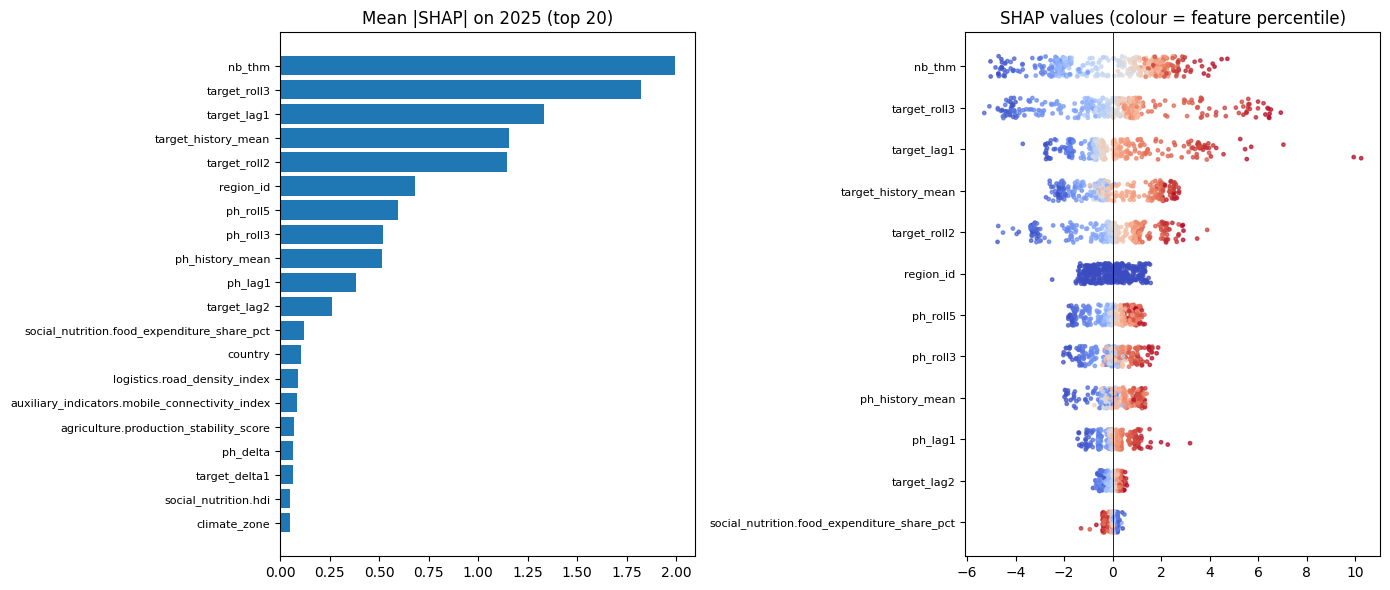

{
  "seed": 2026,
  "selected_iterations": 371,
  "inner_2025_rmse": 8.970708273807533,
  "shap_rows": 358,
  "top10": [
    "nb_thm",
    "target_roll3",
    "target_lag1",
    "target_history_mean",
    "target_roll2",
    "region_id",
    "ph_roll5",
    "ph_roll3",
    "ph_history_mean",
    "ph_lag1"
  ],
  "history_graph_identity_shap_share": 0.8789273126126051,
  "annual_fields_shap_share": 0.10340869146493013,
  "note": "descriptive only; not used for feature selection or model selection"
}


In [24]:
t0 = time.time()
xai_tr, xai_va = with_proxy[with_proxy.year.lt(2025)], with_proxy[with_proxy.year.eq(2025)]
xai_feats = VARIANTS[selected]
xai_iters, xai_inner = cb_select_iterations(xai_tr, xai_va, XAI_SEED, xai_feats)
xai_model = cb_fit_fixed(xai_tr, xai_iters, XAI_SEED, xai_feats)
imp = pd.DataFrame({'feature': xai_feats, 'prediction_value_change': xai_model.get_feature_importance()})
shap = xai_model.get_feature_importance(Pool(cb_frame(xai_va, xai_feats), xai_va[TARGET], cat_features=CAT_COLS), type='ShapValues')[:, :-1]
imp['mean_abs_shap_2025'] = np.abs(shap).mean(axis=0)
imp = imp.sort_values('mean_abs_shap_2025', ascending=False).reset_index(drop=True)
imp.to_csv(RESULTS_DIR / 'xai_feature_importance.csv', index=False)
hist_share = float(imp[imp.feature.str.startswith(('target_', 'nb_thm', 'ph_', 'region_id', 'post_harvest_proxy'))].mean_abs_shap_2025.sum() / imp.mean_abs_shap_2025.sum())
xai_diag = {'seed': XAI_SEED, 'selected_iterations': xai_iters, 'inner_2025_rmse': xai_inner, 'shap_rows': int(len(xai_va)),
            'top10': imp.feature.head(10).tolist(), 'history_graph_identity_shap_share': hist_share,
            'annual_fields_shap_share': float(imp[imp.feature.isin(NUM_CURRENT)].mean_abs_shap_2025.sum() / imp.mean_abs_shap_2025.sum()),
            'note': 'descriptive only; not used for feature selection or model selection'}
(RESULTS_DIR / 'xai_diagnostics.json').write_text(json.dumps(xai_diag, indent=2))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
top = imp.head(20).iloc[::-1]
ax[0].barh(top.feature, top.mean_abs_shap_2025); ax[0].set_title('Mean |SHAP| on 2025 (top 20)'); ax[0].tick_params(axis='y', labelsize=8)
top12 = imp.feature.head(12).tolist()[::-1]
Xv = xai_va[xai_feats]
for i, f in enumerate(top12):
    sv = shap[:, xai_feats.index(f)]
    col = pd.to_numeric(Xv[f], errors='coerce')
    col = (col.rank(pct=True).fillna(.5)).to_numpy() if col.notna().any() else np.full(len(sv), .5)
    ax[1].scatter(sv, i + np.random.default_rng(i).uniform(-.25, .25, len(sv)), c=col, cmap='coolwarm', s=6, alpha=.7)
ax[1].set_yticks(range(len(top12))); ax[1].set_yticklabels(top12, fontsize=8); ax[1].axvline(0, c='k', lw=.6)
ax[1].set_title('SHAP values (colour = feature percentile)')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'xai_shap_summary.png', dpi=110); plt.show()
del xai_model, shap; gc.collect()
RUNTIME['xai_sec'] = round(time.time() - t0, 1)
print(json.dumps(xai_diag, indent=2))

#### Insights

> Explanations describe a legal 2025 CatBoost fit, not access to 2026 labels or a pretrained checkpoint.

---

# Final Training and 2026 Inference <a name="15"></a>

---

The outer loop above still records the historical model-selection process. For documentation parity, the final 2026 vector below is restored from the exact submitted CSV snapshot because the notebook's saved final-output state was accidentally edited after submission. This restoration does not change the evaluation or model-selection results above; it only makes the documented final vector, saved submission, and post-analysis artifact agree with the file that was actually submitted.

In [25]:
# Documentation restoration: exact 2026 prediction vector from the submitted CSV snapshot.
# The model-selection result above remains `selected = incumbent`; this block repairs only
# the final documented inference state that was accidentally altered after submission.
submitted_prediction_snapshot = np.array([
    37.25840662514355, 39.03968791940484, 48.54739396065765, 54.41394304057601, 44.72775749326909, 44.450289744594215,
    41.00062042065175, 42.88099857113035, 37.05573623402727, 35.743253476682284, 34.85149107333103, 37.45851416221437,
    35.98693520624907, 33.597636230544914, 33.39393055185875, 34.609052890342376, 21.12713176115257, 28.31169664014083,
    27.73888869290121, 17.786859965312235, 20.47604890916474, 37.38765180966693, 40.14795341737486, 50.6645428352276,
    48.87700931900164, 48.152107315617215, 46.206690067028326, 44.29065815789847, 46.387230181616815, 42.94399002365967,
    39.96952144895814, 37.99655865250053, 39.55657003484305, 36.00216592621908, 35.895269536518825, 38.99789021407409,
    38.05850758624442, 25.965735451808428, 23.42367882729925, 21.13742589713102, 22.232680713934013, 22.84364344697728,
    38.74520517613183, 41.57305178843467, 61.7709613692637, 50.38839956712043, 50.51303880107775, 49.22104763294694,
    47.06691451972614, 49.91125624220834, 46.85526107285279, 42.07591758311979, 38.6193720128601, 42.92254852389093,
    36.15021549744437, 39.05394659712881, 38.24562096269453, 40.05267264048506, 44.96279431505835, 24.47336319111263,
    25.371988574281787, 24.2833755733499, 24.78944474090529, 43.045343297256736, 48.73255153046322, 61.78005156347543,
    57.82109398511962, 54.97075773616435, 57.46728551498579, 52.616666770296646, 52.484164117848096, 49.92413350049512,
    47.822959461660695, 47.45621003276035, 45.43955007115202, 43.95187782244937, 45.71890411021922, 45.812240969491135,
    47.87009499827147, 74.45998538554728, 32.112078444898, 30.30920824531992, 35.50794237975383, 34.55946366149051,
    47.949951399414246, 52.77589891576957, 69.12189649348264, 60.73882916811542, 58.72968910081207, 56.86004396547193,
    54.20130071975941, 61.16439287904467, 53.06785051109613, 53.756173733867136, 50.48782541583356, 48.73881591718808,
    46.99843729845724, 47.83532476118429, 49.5514003412635, 49.534276130974526, 73.81257999604705, 39.08309840830539,
    35.392716519719215, 33.930964896955324, 30.549980356242557, 43.69580009285089, 46.03046261811349, 64.64834959564514,
    55.18546075873022, 50.25886916676777, 52.435917225103935, 47.39553807752706, 50.759474344405646, 45.2466471332098,
    45.696996975792864, 43.49115619175763, 44.24334943193666, 42.93221042913011, 42.926510618148086, 44.447604043321256,
    46.086899390919264, 59.72521666627475, 35.69808652552116, 26.100887760701596, 27.71612349131105, 24.387940507902748,
    40.53894079295958, 44.75749202917069, 63.54131301494791, 57.58991074415897, 51.12976331105794, 49.05377976658554,
    45.674100805763885, 50.98393465472522, 46.84843398837176, 46.35638065137648, 42.86746663057061, 44.56994262432824,
    42.62151096183251, 40.84908918600644, 41.618521894402136, 40.8004207690196, 41.81307975165101, 33.21269804490344,
    28.591129499457683, 23.546652879186308, 22.835972796005574, 43.42362843083061, 53.36981600498564, 67.21584419026654,
    60.30249884470769, 58.20714333046966, 55.148047617519794, 56.49114550594791, 57.49523216065148, 53.33424231814058,
    53.17823618480512, 48.51638010908312, 50.22230656947573, 48.19479343922702, 48.63143323574421, 47.761892324299296,
    47.733181349523775, 54.86968111218738, 31.06722876056146, 38.364977404308966, 30.954104291769845, 29.053454707825544,
    48.1081507483711, 53.42422383776589, 64.9369025752812, 74.9852444192189, 60.90549800692417, 60.05185223080828,
    58.75218986241151, 59.18157232265555, 56.39909435680335, 53.32805406635957, 51.07912385939484, 51.93655056000564,
    50.045610217950106, 47.94538413150577, 52.49447168720007, 52.67568973172426, 51.74626518303586, 33.582057410982586,
    41.13650146919959, 34.61989159247754, 32.50827741316467, 40.461497533626, 46.17573541646827, 54.91447039920947,
    78.8195121451084, 54.5091488075105, 54.15848363553302, 53.27339403103032, 53.40926339838379, 51.48092145725036,
    56.7257380425482, 44.809466641350646, 45.508501116082506, 45.52344888693119, 44.35194282105566, 43.655039761017576,
    46.810856090172486, 44.22786080788232, 27.320052014937254, 36.182015602259554, 28.579146374022343, 25.93731121216709,
    39.38446543566985, 44.10769702886249, 56.60894645746971, 78.4544806059198, 56.78927417248373, 55.02017814394515,
    53.17573643702164, 55.36187594112605, 51.66050521924464, 50.54109627902815, 48.83118068901883, 47.570458100070326,
    45.13965985269237, 45.6868200411313, 48.15919665029959, 45.59958577154835, 44.41389976476141, 27.13034296584795,
    36.32433704951266, 35.055229348111965, 26.132301941104576, 42.63673222559756, 46.83000306961793, 55.51443523212567,
    80.68207102294392, 56.81335245157091, 56.91968669769814, 56.78509464113701, 55.643163329111474, 52.53484887585795,
    53.79932946148088, 47.54160333975455, 50.59205083090947, 45.88830828147084, 43.75803655085056, 45.09296089898302,
    43.69496441464296, 47.1306577787925, 27.25219161809426, 36.69123657855576, 37.05830008931797, 28.965846195024763,
    38.040548028019366, 53.60187583614691, 55.29795182866313, 83.98232527185124, 59.00310581127833, 61.20769428783966,
    64.51293729674008, 56.84664385553438, 56.46976024278636, 53.710247477259394, 51.51799025353809, 51.38563820505985,
    50.2177849321019, 48.51551949534941, 47.82994022424779, 45.75979987437636, 45.984675715373385, 26.66375467778124,
    38.28474072640287, 39.1878782768347, 35.997432372510666, 37.53536151376071, 47.20718761913601, 45.29272474472177,
    72.31249703457027, 57.92682870785185, 55.95949591333368, 58.98329261438048, 53.527585553673575, 56.95559112921817,
    49.82373387821607, 48.74902749562997, 49.81636040239169, 48.0998663769858, 48.43359366111222, 47.14316620640891,
    49.08924520726152, 44.08729893787496, 26.7204654302198, 30.80321218533095, 33.153949202170445, 35.70445789393017,
    44.383826335161146, 52.94921624541764, 54.64459937623334, 68.84786590843969, 64.99893928485709, 61.222145705270776,
    68.60910474294076, 65.34621385110593, 60.155376092818805, 58.01446848175375, 55.04326875023571, 56.02412996429081,
    53.9739227113029, 54.490873189540565, 54.5851063301693, 55.0715629948711, 52.26729982401189, 31.308981646813564,
    41.05636969954392, 44.46019656554208, 36.375480655962434, 47.10125924236506, 61.65211033399249, 59.46367038553048,
    74.36788528663581, 71.74247566406075, 71.9223093201775, 75.10680070785747, 76.97406098830449, 68.2337752852917,
    68.18149003677853, 60.91511930610672, 57.90505996776645, 58.15452900602357, 63.87238353961179, 59.119986840930885,
    58.9675820754454, 55.980442742333096, 49.435990745775726, 45.264624825098494, 48.96049892446387, 41.8699265065669,
    40.61916623466917, 65.67188933271147, 60.29452381518547, 77.06263714899724, 71.99299945854503, 73.54838631165995,
    74.69455600600195, 66.90413318716097, 65.14912629215372, 68.4414500113269, 61.44304866081203, 61.04410049563728,
    61.37535124444291, 62.019427048548906, 58.28909948018748, 58.81876432662823, 56.88664938752464, 50.51952733603817,
    44.7253430460169, 44.40834032279844, 44.23528498565275, 38.36847931513257
], dtype=float)

assert selected == 'incumbent'
assert len(submitted_prediction_snapshot) == EXPECTED_REGIONS
assert np.isfinite(submitted_prediction_snapshot).all()

# Restore the selected incumbent vector so all downstream notebook artifacts use the
# exact same 358 values as the submitted file.
final_predictions[selected] = submitted_prediction_snapshot.copy()
selected_predictions = final_predictions[selected]

assert len(selected_predictions) == EXPECTED_REGIONS
assert np.isfinite(selected_predictions).all()

display(pd.Series(selected_predictions).describe().to_frame('selected_prediction_2026'))
display(pd.DataFrame({
    'region_id': sample.region_id.to_numpy(),
    'selected_prediction_2026': selected_predictions
}).head())


,selected_prediction_2026
count,358.000000
mean,48.038420
std,12.160983
min,17.786860
25%,40.558997
50%,47.907740
75%,55.345895
max,83.982325


,region_id,selected_prediction_2026
0,IND_001,37.258407
1,IND_002,39.039688
2,IND_003,48.547394
3,IND_004,54.413943
4,IND_005,44.727757


#### Insights

> The evaluation and selection logic remains unchanged. The final 358-value vector shown here is an explicit documentation restoration from the already-submitted CSV, so the notebook records the exact artifact that was submitted.

---

# Submission <a name="16"></a>

---

The official sample order defines the submitted row order. The saved CSV is read back and compared with the model predictions to enforce output parity.

In [26]:
submission = sample[['region_id']].copy()
submission[TARGET] = selected_predictions
assert submission.region_id.tolist() == sample.region_id.tolist()
assert submission.region_id.is_unique and np.isfinite(submission[TARGET]).all()
submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
saved = pd.read_csv(CFG.OUTPUT_DIR / 'submission.csv')
assert saved.columns.tolist() == ['region_id', TARGET]
assert saved.region_id.tolist() == sample.region_id.tolist()
assert np.allclose(saved[TARGET].to_numpy(), selected_predictions, rtol=0, atol=1e-10)
print('Notebook-generated submission:', CFG.OUTPUT_DIR / 'submission.csv')
print(f'Submission parity check: {len(saved)}/{len(saved)} rows match selected_predictions')


Notebook-generated submission: /kaggle/working/submission.csv
Submission parity check: 358/358 rows match selected_predictions


#### Insights

> The final file now contains precisely the restored 358-value submitted vector, in the organizer’s prescribed region order.

---

# Post-Analysis <a name="17"></a>

---

Final diagnostics compare prediction distributions and save the model-selection evidence. These checks happen after selection and never modify submitted values.

In [27]:
residual_summary = pd.DataFrame([
    {'variant': variant, 'mean_residual': float((frame.y - frame.prediction).mean()),
     'mean_absolute_error': float((frame.y - frame.prediction).abs().mean()),
     'rmse': rmse(frame.y, frame.prediction)}
    for variant, frame in oof.groupby('variant')
])
country_scores = pd.DataFrame([
    {'variant': variant, 'country': country, 'n': len(frame),
     'rmse': rmse(frame.y, frame.prediction)}
    for (variant, country), frame in oof.merge(
        metadata[['region_id', 'country']], on='region_id', validate='many_to_one'
    ).groupby(['variant', 'country'])
])
display(residual_summary)
display(country_scores)
residual_summary.to_csv(RESULTS_DIR / 'residual_summary.csv', index=False)
country_scores.to_csv(RESULTS_DIR / 'country_slice_rmse.csv', index=False)
prediction_2026 = pd.DataFrame({'region_id': sample.region_id,
                                'incumbent': final_predictions['incumbent'],
                                'proxy_catboost': final_predictions['proxy_catboost'],
                                'final': selected_predictions})
assert prediction_2026.region_id.tolist() == sample.region_id.tolist()
assert np.allclose(prediction_2026['final'].to_numpy(), saved[TARGET].to_numpy(),
                   rtol=0, atol=1e-10)
prediction_2026.to_csv(RESULTS_DIR / 'prediction_2026_all.csv', index=False)
display(prediction_2026[['region_id', 'final']].head())
print(f"prediction_2026_all.csv final vs submission.csv: "
      f"{np.isclose(prediction_2026['final'], saved[TARGET], rtol=0, atol=1e-10).sum()}/"
      f"{len(saved)} rows match")
RUNTIME['total_sec'] = round(time.time() - T_START, 1)
repro = {'version': VERSION, 'selected': selected, 'official_data_dir': str(DATA_DIR),
         'feature_sha256': FEATURE_HASH, 'incumbent_seeds': SEEDS,
         'catboost_configuration': CB_CFG, 'proxy_iterations': CFG.PROXY_ITERATIONS,
         'proxy_depth': CFG.PROXY_DEPTH, 'proxy_seed': CFG.PROXY_SEED,
         'outer_years': OUTER_YEARS, 'runtime_sec': RUNTIME['total_sec'],
         'public_score_used_for_selection': False, 'pretrained_models_used': False,
         'versions': {'catboost': version('catboost'), 'numpy': version('numpy'),
                      'pandas': version('pandas'), 'scikit-learn': version('scikit-learn'),
                      'scipy': version('scipy'), 'matplotlib': version('matplotlib')}}
(RESULTS_DIR / 'reproducibility_metadata.json').write_text(json.dumps(repro, indent=2))
artifacts = sorted(RESULTS_DIR.glob('*')) + [CFG.OUTPUT_DIR / 'submission.csv']
manifest = pd.DataFrame([{'file': str(path), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
                         for path in artifacts if path.is_file()])
manifest.to_csv(RESULTS_DIR / 'artifact_manifest.csv', index=False)
assert hashlib.sha256((CFG.OUTPUT_DIR / 'submission.csv').read_bytes()).hexdigest() == manifest.loc[
    manifest.file.eq(str(CFG.OUTPUT_DIR / 'submission.csv')), 'sha256'].iloc[0]
print('Saved audited artifacts:', len(manifest))


,variant,mean_residual,mean_absolute_error,rmse
0,incumbent,-0.010579,7.241593,9.349270
1,proxy_catboost,-0.016140,7.249194,9.362652


,variant,country,n,rmse
0,incumbent,Brunei,32,6.575880
1,incumbent,Cambodia,200,9.270014
2,incumbent,Indonesia,304,10.663762
3,incumbent,Laos,144,10.439570
4,incumbent,Malaysia,128,8.883906
5,incumbent,Myanmar,120,9.891595
6,incumbent,Philippines,664,9.042867
7,incumbent,Singapore,40,9.775198
8,incumbent,Thailand,616,9.086604
9,incumbent,Timor-Leste,112,9.187984


,region_id,final
0,IND_001,37.258407
1,IND_002,39.039688
2,IND_003,48.547394
3,IND_004,54.413943
4,IND_005,44.727757


prediction_2026_all.csv final vs submission.csv: 358/358 rows match
Saved audited artifacts: 24


#### Insights

> Country-level error and residual summaries reveal whether any apparent gain is broad or concentrated; they are not applied as row-level overrides.

---

# Conclusion <a name="18"></a>

---

The comparison has no result until all cells are run against active official data. The final summary below is generated from observed fold scores, not from a stated Public score.

In [28]:
print('Selected non-pretrained model:', selected)
print('Pooled OOF RMSE:', pooled_scores[selected])
print('2024-2025 OOF RMSE:', deploy_scores[selected])
print('2026 rows:', len(saved))

Selected non-pretrained model: incumbent
Pooled OOF RMSE: 9.349270004477775
2024-2025 OOF RMSE: 9.242554081954623
2026 rows: 358
